# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [3]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.constants import VTI
from sharpelab_nb.thermometry import temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [4]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260714-QC0426'

# Connect Instruments

## Magnet

In [5]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.025 A
Voltage:             : -0.000 V
Output Enabled       : True
Persistent Switch On : False
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [6]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.10s
Sample:    1.133 K
Vaporizer: 0.909 K


## Lock-ins

In [7]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.07s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.07s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [8]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::24::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.mode.set('VOLT')
k_2400_tg.volt.set(0)
k_2400_tg.rangei.set(1e-6)
k_2400_tg.rangev.set(21)
k_2400_tg.volt.step = 0.005
k_2400_tg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [9]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::1::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.mode.set('VOLT')
k_2400_bg.volt.set(0)
k_2400_bg.rangei.set(1e-6)
k_2400_bg.rangev.set(21)
k_2400_bg.volt.step = 0.005
k_2400_bg.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s


## DC205 (Si gate)

In [10]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.03s
range code: 2 (need 2 = ±100 V)
output on:  1


In [11]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [12]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [13]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [14]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [15]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4",  # <-- validate
    "sr2": "B4-B5",  # <-- validate
    "sr3": "T5-B6",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": T_sample(),  # file-based (worker logfile); key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [16]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T2", "drain": "B7",
    "sr1+": "T3", "sr1-": "T4",
    "sr2+": "B4", "sr2-": "B5",
    "sr3+": "T5", "sr3-": "B6",
}

# HERA — session start (2026-07-14)

In [17]:
# HERA exec probe — confirm kernel bound + bring-up committed (no hardware traffic)
print("aliases :", k_tg, "|", k_bg, "|", k_si)
print("B cap   :", magnet.field.vals)
print("TG vals :", k_2400_tg.volt.vals, "| BG vals:", k_2400_bg.volt.vals, "| Si vals:", dc205.smart_voltage.vals)
print("meas_cfg:", sorted(meas_config))
print("WIRING  :", WIRING)

aliases : <Keithley_2400: k_2400_tg> | <Keithley_2400: k_2400_bg> | dc205_smart_voltage
B cap   : <Numbers -8.0<=v<=8.0>
TG vals : <Numbers -6.0<=v<=7.0> | BG vals: <Numbers -4.5<=v<=4.5> | Si vals: <Numbers -50.0<=v<=50.0>
meas_cfg: ['Si (V)', 'bias_resistor', 'bias_voltage', 'comments', 'lockin_freq', 'sample_temperature:', 'sr0', 'sr0_gain', 'sr0_sens', 'sr1', 'sr1_sens', 'sr2', 'sr2_sens', 'sr3', 'sr3_sens']
WIRING  : {'source': 'T2', 'drain': 'B7', 'sr1+': 'T3', 'sr1-': 'T4', 'sr2+': 'B4', 'sr2-': 'B5', 'sr3+': 'T5', 'sr3-': 'B6'}


## HERA — Gate C: gate-current sanity check (liveness + gross safety)

Recipe: `device-init/gate-current-sanity-check.md` (first-session branch — no
designated references exist; `reentry-baseline` explicitly defers to the
device-init path here). Four legs, each Keithley gate 0 → each card limit
(TG +7/−6 V, BG ±4.5 V), other gates parked at 0, **Si held at 0 V** — the
DC205 has no current readback, so a Si leg would be blind on leakage; leakage
watch lives on the Keithley `curr` channels. Geometry ceiling check passes:
±0.5 V/nm × hBN gives TG ±7.8 V, BG ±6.0 V — both card limits sit inside.

Read per leg: lock-in X nonzero and smooth = device alive on that pair; swept
gate current in pA riding the charging slope to the limit = safe; parked gate
current at floor = no cross-gate path. Voltage-channel sensitivity expectation
near CNP-ish kΩ scale is ~2e-5 (device card) — a railed X is a sensitivity
flag, not a device verdict. Drive: card default 0.5 V through 100 MΩ (5 nA)
at ~13 Hz.

Preconditions printed up top (T ≈ 1.1–1.3 K, B ≈ 0, V_si = 0); cell stops on
mismatch. **Cell A ≈ 25–35 min** (4 × 251 pts at 1.2 s settling floor — rig-card
~1.2 s/pt rule; no in-dir calibrating run yet). Run Cell B (nplci reset) only
if every leg looked safe. On any gross current turn-up: interrupt — the
`finally` parks the gate — and stop.


T_sample = 1.133 K   (expect ~1.1-1.3 K base)
B        = +0.0032 T  (expect ~0)
V_si     = +0.000 V   (expect 0)
sr0: tau=0.1 s, slope=24 dB/oct, sens=2.0e-02
sr1: tau=0.1 s, slope=24 dB/oct, sens=2.0e-02
sr2: tau=1 s, slope=24 dB/oct, sens=1.0e-03
sr3: tau=0.3 s, slope=24 dB/oct, sens=1.0e-04
drive: 0.5 V @ 13.142 Hz through 100 MOhm


2026-07-14 13:23:07,384 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 13:23:07,910 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 13:23:07,925 [INFO] Starting sweep with ID 0


2026-07-14 13:23:07,925 [INFO] Minimum duration 0h 5m 1s


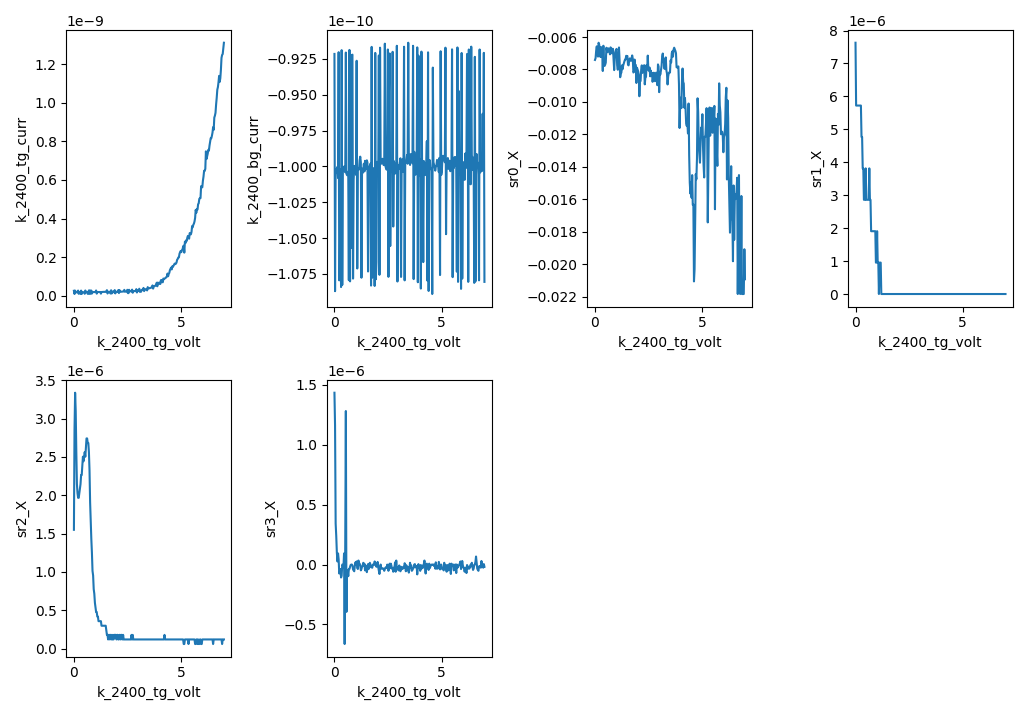

2026-07-14 13:32:56,062 [INFO] Completed in 0h 9m 47s


2026-07-14 13:32:56,062 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\0\data.tsv.gz


2026-07-14 13:32:56,575 [INFO] Ramping k_2400_tg_volt: 7.0 -> 0


2026-07-14 13:33:05,909 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 13:33:06,434 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 13:33:06,443 [INFO] Starting sweep with ID 1


2026-07-14 13:33:06,444 [INFO] Minimum duration 0h 5m 1s


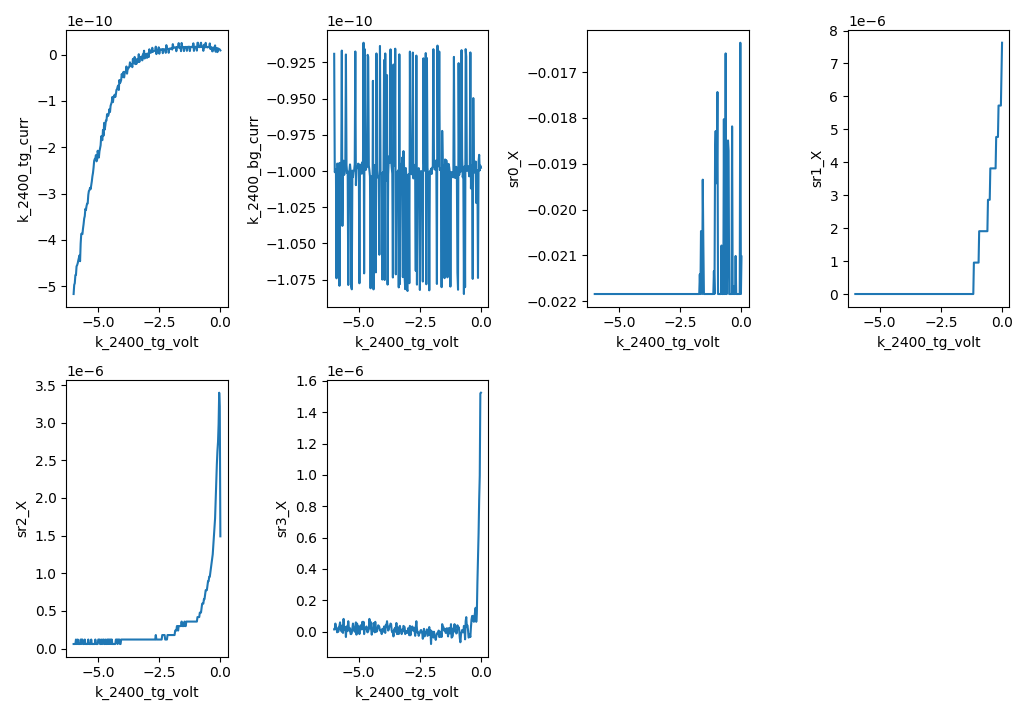

2026-07-14 13:42:54,097 [INFO] Completed in 0h 9m 46s


2026-07-14 13:42:54,097 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\1\data.tsv.gz


2026-07-14 13:42:54,616 [INFO] Ramping k_2400_tg_volt: -6.0 -> 0


2026-07-14 13:43:02,785 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 13:43:03,311 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 13:43:03,320 [INFO] Starting sweep with ID 2


2026-07-14 13:43:03,320 [INFO] Minimum duration 0h 5m 1s


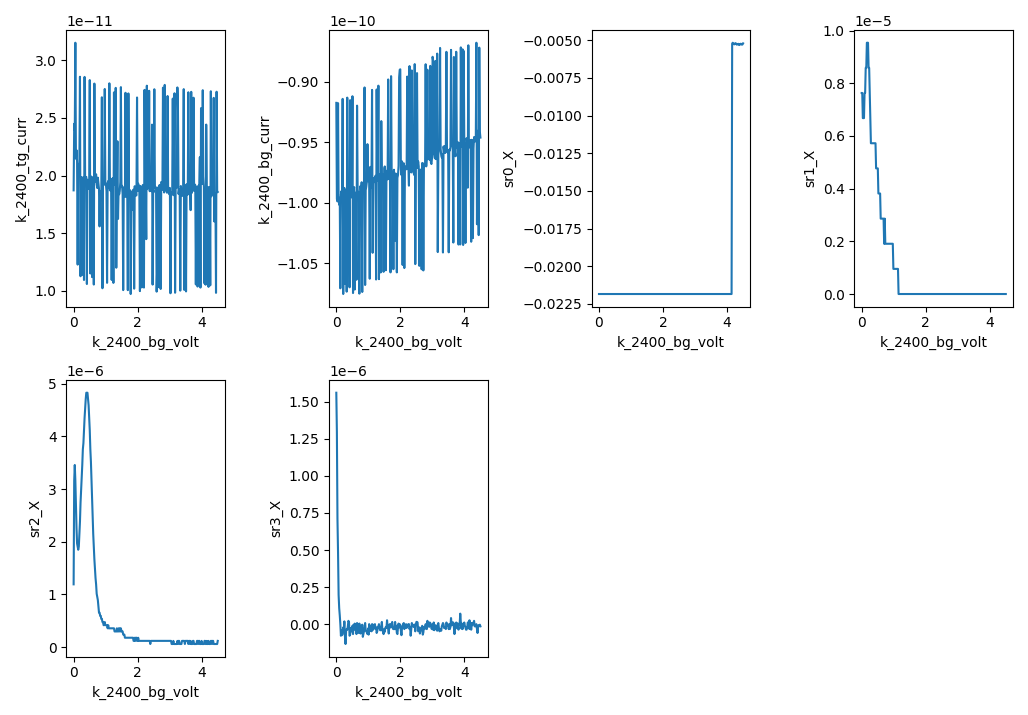

2026-07-14 13:52:46,596 [INFO] Completed in 0h 9m 42s


2026-07-14 13:52:46,597 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\2\data.tsv.gz


2026-07-14 13:52:47,111 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0


2026-07-14 13:52:53,279 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-07-14 13:52:53,809 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-07-14 13:52:53,825 [INFO] Starting sweep with ID 3


2026-07-14 13:52:53,826 [INFO] Minimum duration 0h 5m 1s


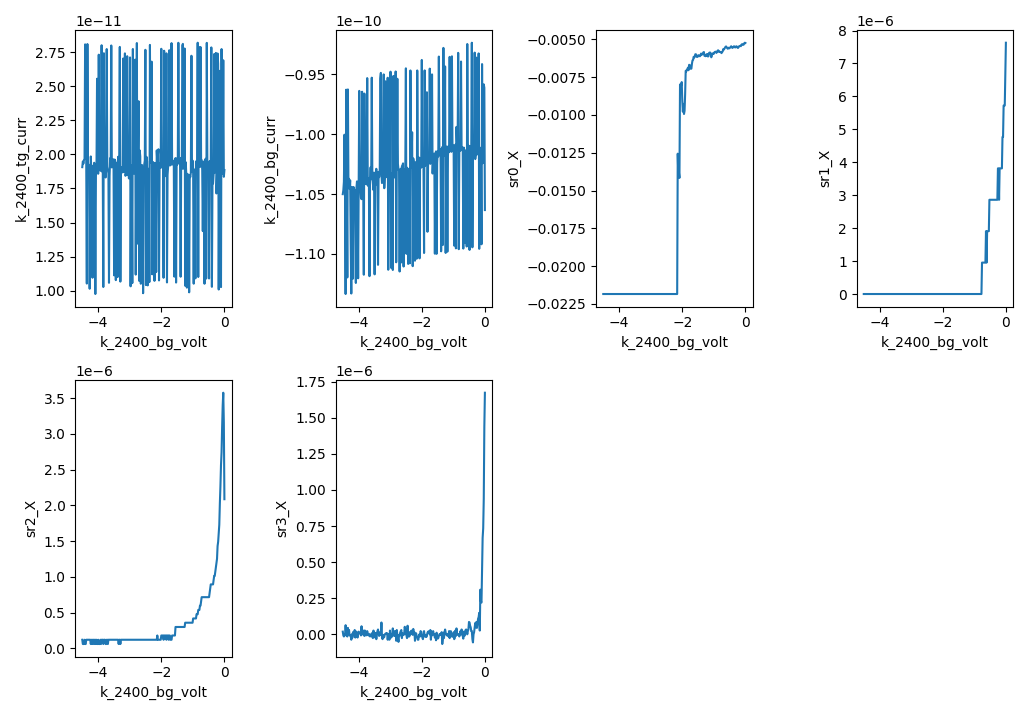

2026-07-14 14:02:36,499 [INFO] Completed in 0h 9m 41s


2026-07-14 14:02:36,499 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\3\data.tsv.gz


2026-07-14 14:02:37,015 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0


all legs complete; TG/BG parked at 0


In [19]:
# === Gate C / Cell A — gate-current-sanity-check: every Keithley gate 0 -> each card limit ===
# Si (DC205) parked at 0 V, no Si leg: no current readback on the DC205; leakage
# watch is the Keithley curr channels. Watch per leg: lock-in X nonzero & smooth
# = alive; swept-gate curr in pA on the charging slope = safe. Gross turn-up ->
# interrupt (finally parks the gate), stop, skip Cell B.

# --- preconditions (state this cell assumes but does not set) ---
T_now = T_sample()
B_now = magnet.field()
V_si = dc205.voltage()
print(f"T_sample = {T_now:.3f} K   (expect ~1.1-1.3 K base)")
print(f"B        = {B_now:+.4f} T  (expect ~0)")
print(f"V_si     = {V_si:+.3f} V   (expect 0)")
for lia in (sr0, sr1, sr2, sr3):
    print(f"{lia.name}: tau={lia.time_constant()} s, slope={lia.filter_slope()} dB/oct, "
          f"sens={lia.sensitivity():.1e}")  # bring-up record: tau/slope live only here (rig card)
assert T_now < 2.0, "sample T out of range"
assert abs(B_now) < 0.02, "field not at zero"
assert abs(V_si) < 1e-2, "Si gate not parked at 0"

sr1.amplitude(0.5)  # card default drive: 0.5 V / 100 MOhm = 5 nA
print(f"drive: {sr1.amplitude()} V @ {sr1.frequency()} Hz through 100 MOhm")

# pA-floor gate-current readback; Cell B resets to 1
k_tg.nplci(10)
k_bg.nplci(10)

meas_config['comments'] = 'gate-current-sanity-check: TG/BG legs 0->card limits, Si parked 0 V, B=0'

# one leg per gate per polarity, (gate, endpoint) -- endpoints are the committed card limits
legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),
    (k_bg, BG_MAX), (k_bg, BG_MIN),
]
n_pts, delay = 251, 1.2  # 4*tau = 1.2 s settling floor (device card)

for gate, v_end in legs:
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}')
    s.add_comment(f'leg: 0 -> {v_end:+g} V (card limit)')

    # park both Keithley gates at 0 (the swept one starts from 0)
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(T_sample)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    for lia in (sr0, sr1, sr2, sr3):
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)

    try:
        s.sweep(gate.volt, np.linspace(0, v_end, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)

print("all legs complete; TG/BG parked at 0")


In [ ]:
# === Gate C / Cell B — reset gate-current nplci (run ONLY if every leg looked safe) ===
k_tg.nplci(1)
k_bg.nplci(1)
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)


## HERA — E1 engaged (grant recorded)
Kernel-binding probe: read-only namespace + instrument reads; confirms this tool surface executes on the operator's instrument-carrying kernel before any autonomous measurement.

In [18]:
# HERA E1 kernel-binding probe — read-only, no instrument writes
print("bound instruments:", type(magnet).__name__, type(dc205).__name__,
      type(k_2400_tg).__name__, type(sr0).__name__)
print("B        :", magnet.field(), "T")
print("T_sample :", T_sample(), "K")
print("V_si     :", dc205.voltage(), "V (expect 0)")
print("V_tg/V_bg:", k_tg.volt(), "/", k_bg.volt(), "V")
print("validators:", k_2400_tg.volt.vals, k_2400_bg.volt.vals,
      dc205.smart_voltage.vals, magnet.field.vals)


bound instruments: FastBi1K5 SRS_DC205 Keithley_2400 SR830
B        : 0.0032094383561643834 T
T_sample : 1.133 K
V_si     : 0.0 V (expect 0)
V_tg/V_bg: 0.0 / 0.0 V
validators: <Numbers -6.0<=v<=7.0> <Numbers -4.5<=v<=4.5> <Numbers -50.0<=v<=50.0> <Numbers -8.0<=v<=8.0>


## HERA — device health re-check at reduced extents (post-excursion baseline)

Recipe: `device-init/reentry-baseline` (reduced re-run after an intervention —
here the +7 V / 1.3 nA and −6 V / 0.5 nA TG excursions of runs 0/1). Four legs
at the proposed design extents — **TG 0→±4.0 V, BG 0→±4.5 V** — identical
acquisition to runs 0–3 (same drive 0.5 V/13 Hz, delay 1.2 s, nplci 10 — Cell B
still deliberately unrun so offsets match). References: **this session's runs
0–3, in-range portions** (pre/immediately-post-excursion state).

Pass bands (quantitative, per reentry-baseline step 4):
- **Leakage floor**: TG within ~±50 pA of its +20 pA offset over the full ±4 V;
  BG within ~±50 pA of its −100 pA offset. Any exponential turn-up **inside**
  ±4 V that wasn't there in runs 0/1 = FAIL (dielectric degraded).
- **Resistance scale**: sr1/sr2 |X| ratio to reference at matched V within ~2×
  (hysteresis between legs was already present pre-excursion — sr0 railed from
  leg 2 on — so shape and positions carry the verdict more than absolute scale).
- **Feature positions**: neutrality-like maxima on sr1/sr2 within a few steps
  (≲0.1 V) of the run-0/1 positions.
- **Trace shape**: same feature set, no new structure.

**~26 min** (4 × 151 pts × 2.33 s/pt measured on runs 0–3, + ramp-backs).
Watch the live gate-current plots; interrupt on any turn-up — legs stay inside
the range runs 0/1 showed clean. I compare against reference quantitatively
when the data lands and state pass/fail per check.


T_sample = 1.137 K   (expect ~1.1-1.3 K)
B        = +0.0032 T  (expect ~0)
V_si     = +0.000 V   (expect 0)
V_tg/V_bg = +0.000 / +0.000 V (expect 0/0)
2026-07-14 14:16:57,238 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0
2026-07-14 14:16:57,758 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0
2026-07-14 14:16:57,773 [INFO] Starting sweep with ID 4
2026-07-14 14:16:57,774 [INFO] Minimum duration 0h 3m 1s


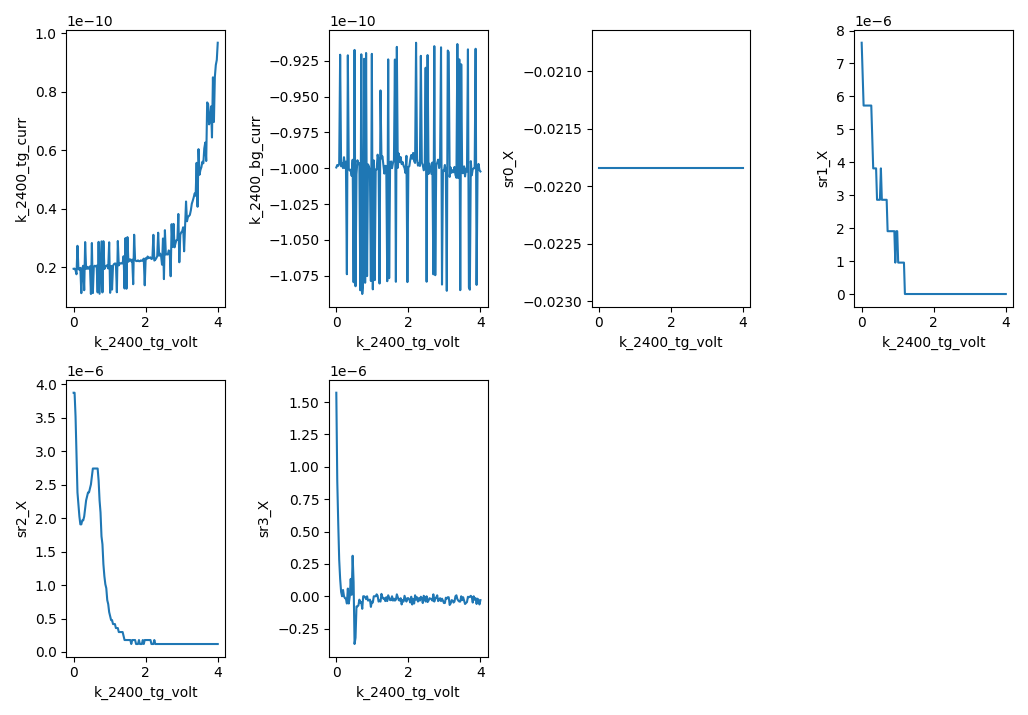

2026-07-14 14:22:50,006 [INFO] Completed in 0h 5m 51s
2026-07-14 14:22:50,010 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\4\data.tsv.gz
2026-07-14 14:22:50,521 [INFO] Ramping k_2400_tg_volt: 4.0 -> 0
2026-07-14 14:22:56,056 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0
2026-07-14 14:22:56,587 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0
2026-07-14 14:22:56,597 [INFO] Starting sweep with ID 5
2026-07-14 14:22:56,598 [INFO] Minimum duration 0h 3m 1s


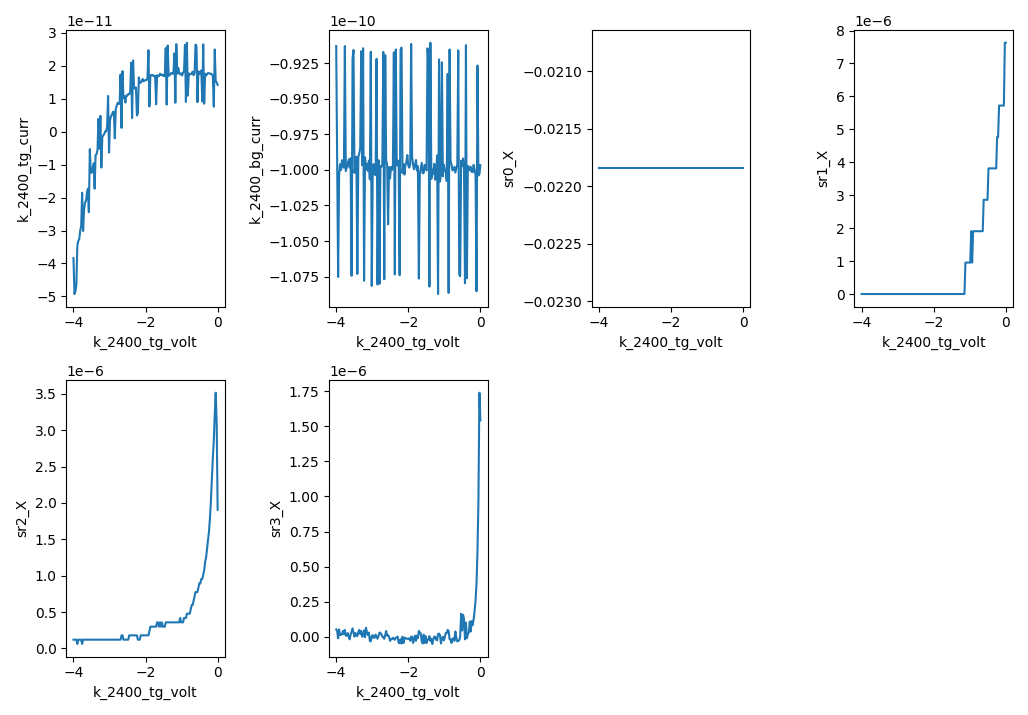

2026-07-14 14:28:51,997 [INFO] Completed in 0h 5m 54s
2026-07-14 14:28:51,998 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\5\data.tsv.gz
2026-07-14 14:28:52,516 [INFO] Ramping k_2400_tg_volt: -4.0 -> 0
2026-07-14 14:28:58,142 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0
2026-07-14 14:28:58,663 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0
2026-07-14 14:28:58,674 [INFO] Starting sweep with ID 6
2026-07-14 14:28:58,674 [INFO] Minimum duration 0h 3m 1s


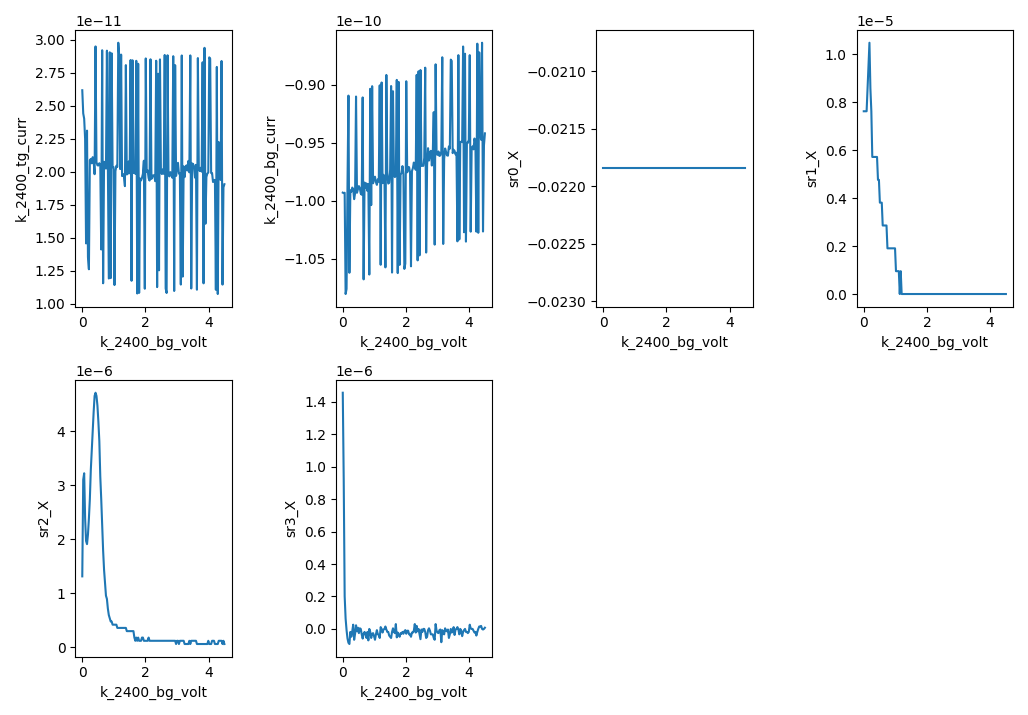

2026-07-14 14:34:51,185 [INFO] Completed in 0h 5m 51s
2026-07-14 14:34:51,186 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\6\data.tsv.gz
2026-07-14 14:34:51,705 [INFO] Ramping k_2400_bg_volt: 4.5 -> 0
2026-07-14 14:34:57,871 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0
2026-07-14 14:34:58,395 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0
2026-07-14 14:34:58,404 [INFO] Starting sweep with ID 7
2026-07-14 14:34:58,404 [INFO] Minimum duration 0h 3m 1s


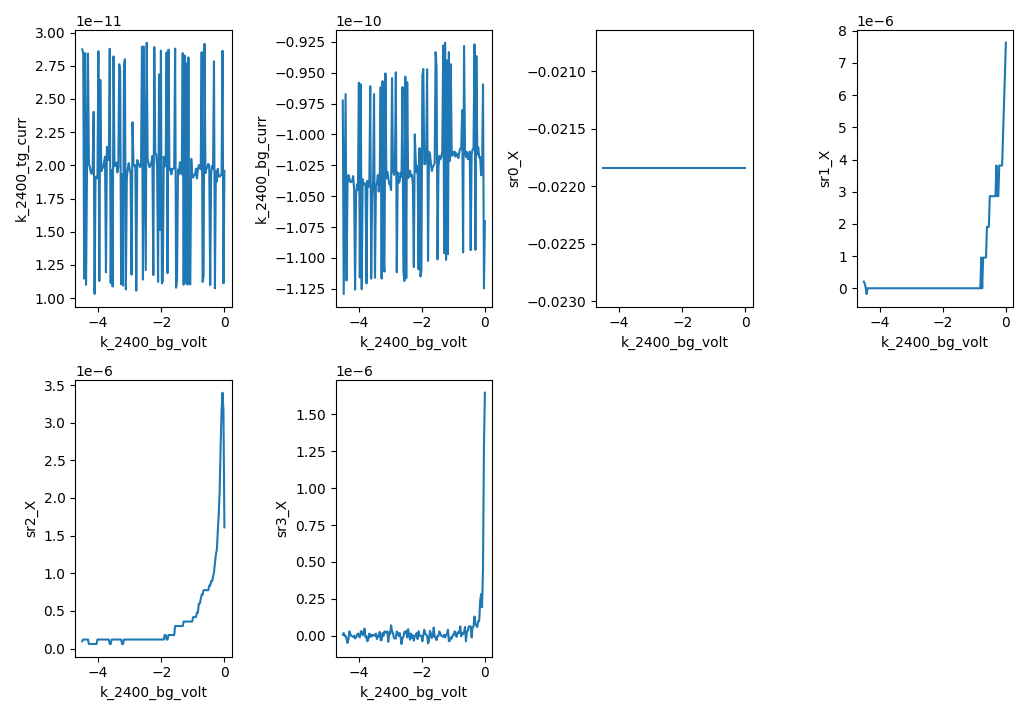

2026-07-14 14:40:56,217 [INFO] Completed in 0h 5m 57s
2026-07-14 14:40:56,217 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260714-QC0426\data\7\data.tsv.gz
2026-07-14 14:40:56,737 [INFO] Ramping k_2400_bg_volt: -4.5 -> 0
health-check legs complete; TG/BG parked at 0


In [20]:
# === Device health re-check: reduced-extent legs (reentry-baseline) ===
# References: this session's runs 0-3 (in-range portions). Identical acquisition:
# drive 0.5 V / 13 Hz, delay 1.2 s, nplci 10 (offsets match runs 0-3; Cell B still held).

# --- preconditions (state this cell assumes but does not set) ---
T_now = T_sample()
B_now = magnet.field()
V_si = dc205.voltage()
print(f"T_sample = {T_now:.3f} K   (expect ~1.1-1.3 K)")
print(f"B        = {B_now:+.4f} T  (expect ~0)")
print(f"V_si     = {V_si:+.3f} V   (expect 0)")
print(f"V_tg/V_bg = {k_tg.volt():+.3f} / {k_bg.volt():+.3f} V (expect 0/0)")
assert T_now < 2.0 and abs(B_now) < 0.02 and abs(V_si) < 1e-2

sr1.amplitude(0.5)
k_tg.nplci(10)
k_bg.nplci(10)

meas_config['bias_voltage'] = sr1.amplitude()   # refresh stale key (was frozen at bring-up residual)
meas_config['comments'] = 'reentry-baseline: post-excursion health check, TG/BG legs at design extents, Si 0 V, B=0'

legs = [
    (k_tg, +4.0), (k_tg, -4.0),
    (k_bg, +4.5), (k_bg, -4.5),
]
n_pts, delay = 151, 1.2

for gate, v_end in legs:
    s = sweep.AsyncStation(meas_config)
    s.add_comment('reentry-baseline')
    s.add_comment(f'gate: {gate.name}; leg: 0 -> {v_end:+g} V (design extent)')
    s.add_comment('references: runs 0-3 in-range portions (same acquisition)')

    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(T_sample)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    for lia in (sr0, sr1, sr2, sr3):
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)

    try:
        s.sweep(gate.volt, np.linspace(0, v_end, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)

print("health-check legs complete; TG/BG parked at 0")


## HERA — reset rig state to session-start expectations (handoff to fresh session)

Undo this session's acquisition-state changes and put the lock-ins at the
device card's documented settings, so the next bring-up finds the rig where
its card says it should be:

- Keithley `nplci` 10 → **1** (the held Cell-B reset).
- Lock-ins → card values: **τ = 0.3 s, 24 dB/oct** on all four; sensitivities
  **sr1/sr2/sr3 = 2e-5** (CNP/gate-map scale), **sr0 = 1e-2** (card table).
  Caveat carried in the notes: at 1e-2 the drain channel still clips ≥ ~11 nA
  — the new session's bring-up may want 5e-2 until the bias chain is
  identified.
- Drive: sr1 amplitude **0.5 V** (card default), frequency untouched (~13 Hz).
- Verify gates/Si/field parked: prints expected vs actual, ends with a full
  state readback. ~15 s, no sweeps.


In [21]:
# === Reset acquisition state to session-start expectations (handoff) ===
# nplci back to 1 (held Cell B), lock-ins to card values, drive at card default.

k_tg.nplci(1)
k_bg.nplci(1)

for lia in (sr0, sr1, sr2, sr3):
    lia.time_constant(0.3)
    lia.filter_slope(24)
sr0.sensitivity(1e-2)   # card table (metallic-regime drain); note: clips >= ~11 nA
sr1.sensitivity(2e-5)   # CNP / gate-map scale (card)
sr2.sensitivity(2e-5)
sr3.sensitivity(2e-5)
sr1.amplitude(0.5)      # card default drive (0.5 V through bias resistor)

print("--- state readback ---")
print(f"nplci    : tg={k_tg.nplci()}, bg={k_bg.nplci()}")
for lia in (sr0, sr1, sr2, sr3):
    print(f"{lia.name}: tau={lia.time_constant()} s, slope={lia.filter_slope()} dB/oct, "
          f"sens={lia.sensitivity():.1e}, ")
print(f"drive    : {sr1.amplitude()} V @ {sr1.frequency():.3f} Hz")
print(f"gates    : V_tg={k_tg.volt():+.3f} V, V_bg={k_bg.volt():+.3f} V (expect 0/0)")
print(f"Si       : {dc205.voltage():+.3f} V (expect 0), range={dc205.voltage_range()} (RNGE 2), output={dc205.output()}")
print(f"field    : {magnet.field():+.4f} T (expect ~0)")
print(f"T_sample : {T_sample():.3f} K")
print(f"validators: TG {k_2400_tg.volt.vals}, BG {k_2400_bg.volt.vals}, Si {dc205.smart_voltage.vals}, B {magnet.field.vals}")


--- state readback ---
nplci    : tg=1.0, bg=1.0
sr0: tau=0.3 s, slope=24 dB/oct, sens=1.0e-02, 
sr1: tau=0.3 s, slope=24 dB/oct, sens=2.0e-05, 
sr2: tau=0.3 s, slope=24 dB/oct, sens=2.0e-05, 
sr3: tau=0.3 s, slope=24 dB/oct, sens=2.0e-05, 
drive    : 0.5 V @ 13.142 Hz
gates    : V_tg=+0.000 V, V_bg=+0.000 V (expect 0/0)
Si       : +0.000 V (expect 0), range=2 (RNGE 2), output=1
field    : +0.0033 T (expect ~0)
T_sample : 1.148 K
validators: TG <Numbers -6.0<=v<=7.0>, BG <Numbers -4.5<=v<=4.5>, Si <Numbers -50.0<=v<=50.0>, B <Numbers -8.0<=v<=8.0>
